# Fine-tuning YOLOv5 — Detección de nadadores

Este notebook hace fine-tuning del modelo del repo [DBDoco/yolo-swimmer-detection](https://github.com/DBDoco/yolo-swimmer-detection) (YOLOv5s, entrenado originalmente a `imgsz=960`) y después lo evalúa contra un set de test independiente.

**Pensado para correr en Google Colab con GPU** (Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4, gratis). Tu PC solo tiene GPU integrada Intel, así que en local esto sería demasiado lento.

### Datasets que usa (subilos a tu Google Drive antes de correr, son grandes):
- **`dataset.zip`** (1.8 GB): formato YOLO estándar (`images/test` + `labels/test`, clases `persona`/`swimmer`). Solo trae una carpeta llamada "test" con todo junto — el notebook arma automáticamente un split train/val 85/15 para el fine-tuning.
- **`My First Project.yolov5-obb.zip`** (400 MB): 750 imágenes con labels en formato OBB (polígonos de 4 puntos, carpeta `valid/`). Este set **no se usa para entrenar** — queda aparte como test independiente para medir el rendimiento real del modelo ya entrenado. El notebook convierte esos polígonos a formato YOLO estándar (son rectángulos alineados a los ejes, así que la conversión es directa) antes de evaluar.

### Antes de correr:
1. Subí ambos `.zip` a tu Google Drive (raíz de "Mi unidad", o ajustá las rutas en la celda de montaje).
2. Activá GPU (arriba).
3. Corré las celdas en orden.


In [2]:
#@title Anti-desconexión por inactividad
from IPython.display import Javascript
display(Javascript('''
function ClickConnect(){
  console.log("Ping para evitar desconexión por inactividad");
  document.querySelector("colab-connect-button")?.click();
}
setInterval(ClickConnect, 60000);
'''))

<IPython.core.display.Javascript object>

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
#@title 1. Verificar GPU
!nvidia-smi


Wed Oct  7 18:37:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             42W /   70W |    4123MiB /  15360MiB |     65%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
#@title 2. Clonar YOLOv5 e instalar dependencias
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
%pip install -qr requirements.txt
import torch
print('Torch:', torch.__version__, '| CUDA disponible:', torch.cuda.is_available())


fatal: destination path 'yolov5' already exists and is not an empty directory.
/content/yolov5
Torch: 2.11.0+cu130 | CUDA disponible: True


In [6]:
#@title 3. Descargar los .zip desde Drive
!pip install -q gdown
import gdown, re, os

def gdrive_id_from_link(link):
    m = re.search(r'/d/([a-zA-Z0-9_-]+)', link) or re.search(r'id=([a-zA-Z0-9_-]+)', link)
    if not m:
        raise ValueError(f'No pude sacar el ID de Drive de: {link}')
    return m.group(1)

DATASET_ZIP_LINK = 'https://drive.google.com/file/d/1rxfce3XfroVK-UKUKzmUUb608GJuCimy/view?usp=sharing'
DATASET_ZIP = '/content/dataset.zip'
gdown.download(id=gdrive_id_from_link(DATASET_ZIP_LINK), output=DATASET_ZIP, quiet=False)

OBB_TEST_ZIP_LINK = 'https://drive.google.com/file/d/1k56M_mnOeRbdj_ClRWZDdskTkl53SqKF/view?usp=sharing'
OBB_TEST_ZIP = '/content/obb_test.zip'
gdown.download(id=gdrive_id_from_link(OBB_TEST_ZIP_LINK), output=OBB_TEST_ZIP, quiet=False)

assert os.path.exists(DATASET_ZIP), 'Fallo la descarga de dataset.zip'
assert os.path.exists(OBB_TEST_ZIP), 'Fallo la descarga de My First Project.yolov5-obb.zip'
print('OK -> dataset.zip:', round(os.path.getsize(DATASET_ZIP)/1e6, 1), 'MB |',
      'obb_test.zip:', round(os.path.getsize(OBB_TEST_ZIP)/1e6, 1), 'MB')


Downloading...
From (original): https://drive.google.com/uc?id=1rxfce3XfroVK-UKUKzmUUb608GJuCimy
From (redirected): https://drive.google.com/uc?id=1rxfce3XfroVK-UKUKzmUUb608GJuCimy&confirm=t&uuid=662e8756-c6e2-43fb-922c-a2bf7bfa02b7
To: /content/dataset.zip
100%|██████████| 1.88G/1.88G [00:34<00:00, 54.6MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1k56M_mnOeRbdj_ClRWZDdskTkl53SqKF
From (redirected): https://drive.google.com/uc?id=1k56M_mnOeRbdj_ClRWZDdskTkl53SqKF&confirm=t&uuid=a097a5fe-30dc-4e35-9820-f2a251fc4497
To: /content/obb_test.zip
100%|██████████| 401M/401M [00:07<00:00, 53.0MB/s] 

OK -> dataset.zip: 1878.8 MB | obb_test.zip: 401.0 MB


In [7]:
#@title 4. Extraer dataset.zip (dataset completo, se usará TODO para entrenar)
import zipfile

with zipfile.ZipFile(DATASET_ZIP, 'r') as z:
    z.extractall('/content/data_raw')

!find /content/data_raw -maxdepth 3 -type d
print()
!ls /content/data_raw/dataset/images/test | wc -l
!ls /content/data_raw/dataset/labels/test | wc -l
!cat /content/data_raw/dataset/nombres_clases.txt


/content/data_raw
/content/data_raw/dataset
/content/data_raw/dataset/images
/content/data_raw/dataset/images/test
/content/data_raw/dataset/labels
/content/data_raw/dataset/labels/test

3518
3500
persona
swimmer


In [8]:
#@title 5. Descargar los pesos ya entrenados del repo (punto de partida del fine-tuning)
!wget -q -O /content/yolov5/pretrained_best.pt "https://raw.githubusercontent.com/DBDoco/yolo-swimmer-detection/main/models/exp5/weights/best.pt"
!ls -la /content/yolov5/pretrained_best.pt


-rw-r--r-- 1 root root 14581032 Oct  7 18:39 /content/yolov5/pretrained_best.pt


In [9]:
#@title 6. Arreglar el checkpoint (fue guardado en Windows, hay que adaptarlo a Linux)
import pathlib, torch

_original_windows_path = pathlib.WindowsPath
pathlib.WindowsPath = pathlib.PosixPath  # parche temporal

ckpt = torch.load('/content/yolov5/pretrained_best.pt', map_location='cpu', weights_only=False)

pathlib.WindowsPath = _original_windows_path  # restaurar

torch.save(ckpt, '/content/yolov5/pretrained_best_fixed.pt')
print('Checkpoint arreglado y guardado en pretrained_best_fixed.pt')


Checkpoint arreglado y guardado en pretrained_best_fixed.pt


In [10]:
DATASET_ZIP = '/content/dataset.zip'
OBB_TEST_ZIP = '/content/obb_test.zip'


In [11]:
#@title 10. Extraer el set de test OBB
import zipfile
with zipfile.ZipFile(OBB_TEST_ZIP, 'r') as z:
    z.extractall('/content/obb_raw')

!find /content/obb_raw -maxdepth 3


/content/obb_raw
/content/obb_raw/data.yaml
/content/obb_raw/valid
/content/obb_raw/valid/labelTxt
/content/obb_raw/valid/labelTxt/training3_frame1008_jpg.rf.dijaXItMr4pGSlkcNhc6.txt
/content/obb_raw/valid/labelTxt/training3_frame0830_jpg.rf.h3TsYUvqvelCFjiCiWWi.txt
/content/obb_raw/valid/labelTxt/training3_frame0346_jpg.rf.rMY5WMkyGwkcFprXmB5T.txt
/content/obb_raw/valid/labelTxt/training2_frame1040_jpg.rf.xrkST4Akac6TdGssVKZi.txt
/content/obb_raw/valid/labelTxt/training2_frame0478_jpg.rf.AI5Xy6TV0MgPYGlC4MK2.txt
/content/obb_raw/valid/labelTxt/training_frame0223_jpg.rf.1US5n7y3L5KIPyo2EMzU.txt
/content/obb_raw/valid/labelTxt/training3_frame1017_jpg.rf.jI85sapeEujmMbUqmLCr.txt
/content/obb_raw/valid/labelTxt/training_frame2396_jpg.rf.I6Y6cbXIVjvnhQ8Q3nJW.txt
/content/obb_raw/valid/labelTxt/training2_frame0407_jpg.rf.F6rQNoIBGSBCZUkKcwTN.txt
/content/obb_raw/valid/labelTxt/training_frame2332_jpg.rf.XSiwdY8c3m6urNnUZXOs.txt
/content/obb_raw/valid/labelTxt/training_frame0077_jpg.rf.qePPtC

In [12]:
import os
print(os.path.exists('/content/obb_test.zip'))
print(os.path.exists('/content/dataset.zip'))


True
True


In [13]:
#@title 11. Convertir labels OBB (polígono) -> YOLO (class x_center y_center w h normalizado)
from PIL import Image as PILImage
from pathlib import Path
import shutil

CLASS_NAMES = ['persona', 'swimmer']
name_to_id = {n: i for i, n in enumerate(CLASS_NAMES)}

obb_root = Path('/content/obb_raw/valid')
out_img_dir = Path('/content/obb_test/images')
out_lbl_dir = Path('/content/obb_test/labels')
out_img_dir.mkdir(parents=True, exist_ok=True)
out_lbl_dir.mkdir(parents=True, exist_ok=True)

n_ok, n_boxes, skipped = 0, 0, 0
for img_path in sorted((obb_root / 'images').iterdir()):
    if img_path.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
        continue
    lbl_path = obb_root / 'labelTxt' / (img_path.stem + '.txt')
    shutil.copy(img_path, out_img_dir / img_path.name)

    if not lbl_path.exists():
        (out_lbl_dir / (img_path.stem + '.txt')).write_text('')
        n_ok += 1
        continue

    with PILImage.open(img_path) as im:
        w_img, h_img = im.size

    lines = []
    for raw_line in lbl_path.read_text().splitlines():
        parts = raw_line.split()
        if len(parts) < 9:
            continue
        coords = list(map(float, parts[:8]))
        cls_name = parts[8]
        if cls_name not in name_to_id:
            skipped += 1
            continue
        xs = coords[0::2]
        ys = coords[1::2]
        x_min, x_max = min(xs), max(xs)
        y_min, y_max = min(ys), max(ys)
        x_c = ((x_min + x_max) / 2) / w_img
        y_c = ((y_min + y_max) / 2) / h_img
        bw = (x_max - x_min) / w_img
        bh = (y_max - y_min) / h_img
        lines.append(f'{name_to_id[cls_name]} {x_c:.6f} {y_c:.6f} {bw:.6f} {bh:.6f}')
        n_boxes += 1

    (out_lbl_dir / (img_path.stem + '.txt')).write_text('\n'.join(lines))
    n_ok += 1

print(f'Imágenes convertidas: {n_ok} | cajas totales: {n_boxes} | líneas con clase desconocida ignoradas: {skipped}')


Imágenes convertidas: 750 | cajas totales: 5244 | líneas con clase desconocida ignoradas: 0


In [14]:
#@title 12. data.yaml v3 — train: dataset.zip completo | val: My First Project.yolov5-obb
data_yaml_v3 = """\
path: /content
train: data_raw/dataset/images/test
val: obb_test/images

nc: 2
names: ['persona', 'swimmer']
"""

with open('/content/data_v3.yaml', 'w') as f:
    f.write(data_yaml_v3)

print(data_yaml_v3)


path: /content
train: data_raw/dataset/images/test
val: obb_test/images

nc: 2
names: ['persona', 'swimmer']



In [15]:
import os
print(os.path.exists('/content/yolov5/val.py'))


True


In [16]:
%cd /content/yolov5

/content/yolov5


In [17]:
#@title Verificar que no haya ningún entrenamiento corriendo todavía
!ps aux | grep train.py


root       45316 84.1  5.7 4257116 764720 ?      Dl   18:39   0:04 python3 -u train.py --resume /content/drive/MyDrive/yolo_runs/swimmer_finetune_v3/weights/last.pt
root       45336  0.0  0.0   7348  3592 ?        S    18:39   0:00 /bin/bash -c ps aux | grep train.py
root       45338  0.0  0.0   6684  2416 ?        S    18:39   0:00 grep train.py


In [18]:
%%writefile /content/train_wrapper_v3.py
import os, subprocess, time

os.environ['WANDB_MODE'] = 'disabled'

RUN_DIR = '/content/drive/MyDrive/yolo_runs/swimmer_finetune_v3'
LAST_PT = f'{RUN_DIR}/weights/last.pt'
INIT_WEIGHTS = '/content/yolov5/pretrained_best_fixed.pt'

os.chdir('/content/yolov5')

max_retries = 20
for attempt in range(1, max_retries + 1):
    if os.path.exists(LAST_PT):
        print(f'[Intento {attempt}] Retomando desde checkpoint: {LAST_PT}', flush=True)
        cmd = ['python', '-u', 'train.py', '--resume', LAST_PT]
    else:
        print(f'[Intento {attempt}] Arrancando entrenamiento limpio (train=dataset completo, val=OBB)', flush=True)
        cmd = [
            'python', '-u', 'train.py',
            '--img', '960', '--batch', '16', '--epochs', '50',
            '--data', '/content/data_v3.yaml',
            '--weights', INIT_WEIGHTS,
            '--freeze', '10', '--patience', '15',
            '--project', '/content/drive/MyDrive/yolo_runs',
            '--name', 'swimmer_finetune_v3', '--exist-ok',
        ]

    returncode = subprocess.call(cmd)

    if returncode == 0:
        print('✅ Entrenamiento terminado con éxito.', flush=True)
        break
    print(f'⚠️ Se cortó (código {returncode}). Reintentando en 10s...', flush=True)
    time.sleep(10)
else:
    print('❌ Se llegó al máximo de reintentos.', flush=True)


Overwriting /content/train_wrapper_v3.py


In [ ]:
#@title 8. Entrenar (v3)
!python -u /content/train_wrapper_v3.py


[Intento 1] Retomando desde checkpoint: /content/drive/MyDrive/yolo_runs/swimmer_finetune_v3/weights/last.pt
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791398384.589027   45349 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=data/coco128.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=100, batch_size=16, imgsz=640, rect=False, resume=/content/drive/MyDrive/yolo_runs/swimmer_finetune_v3/weights/last.pt, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=exp, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1

: 

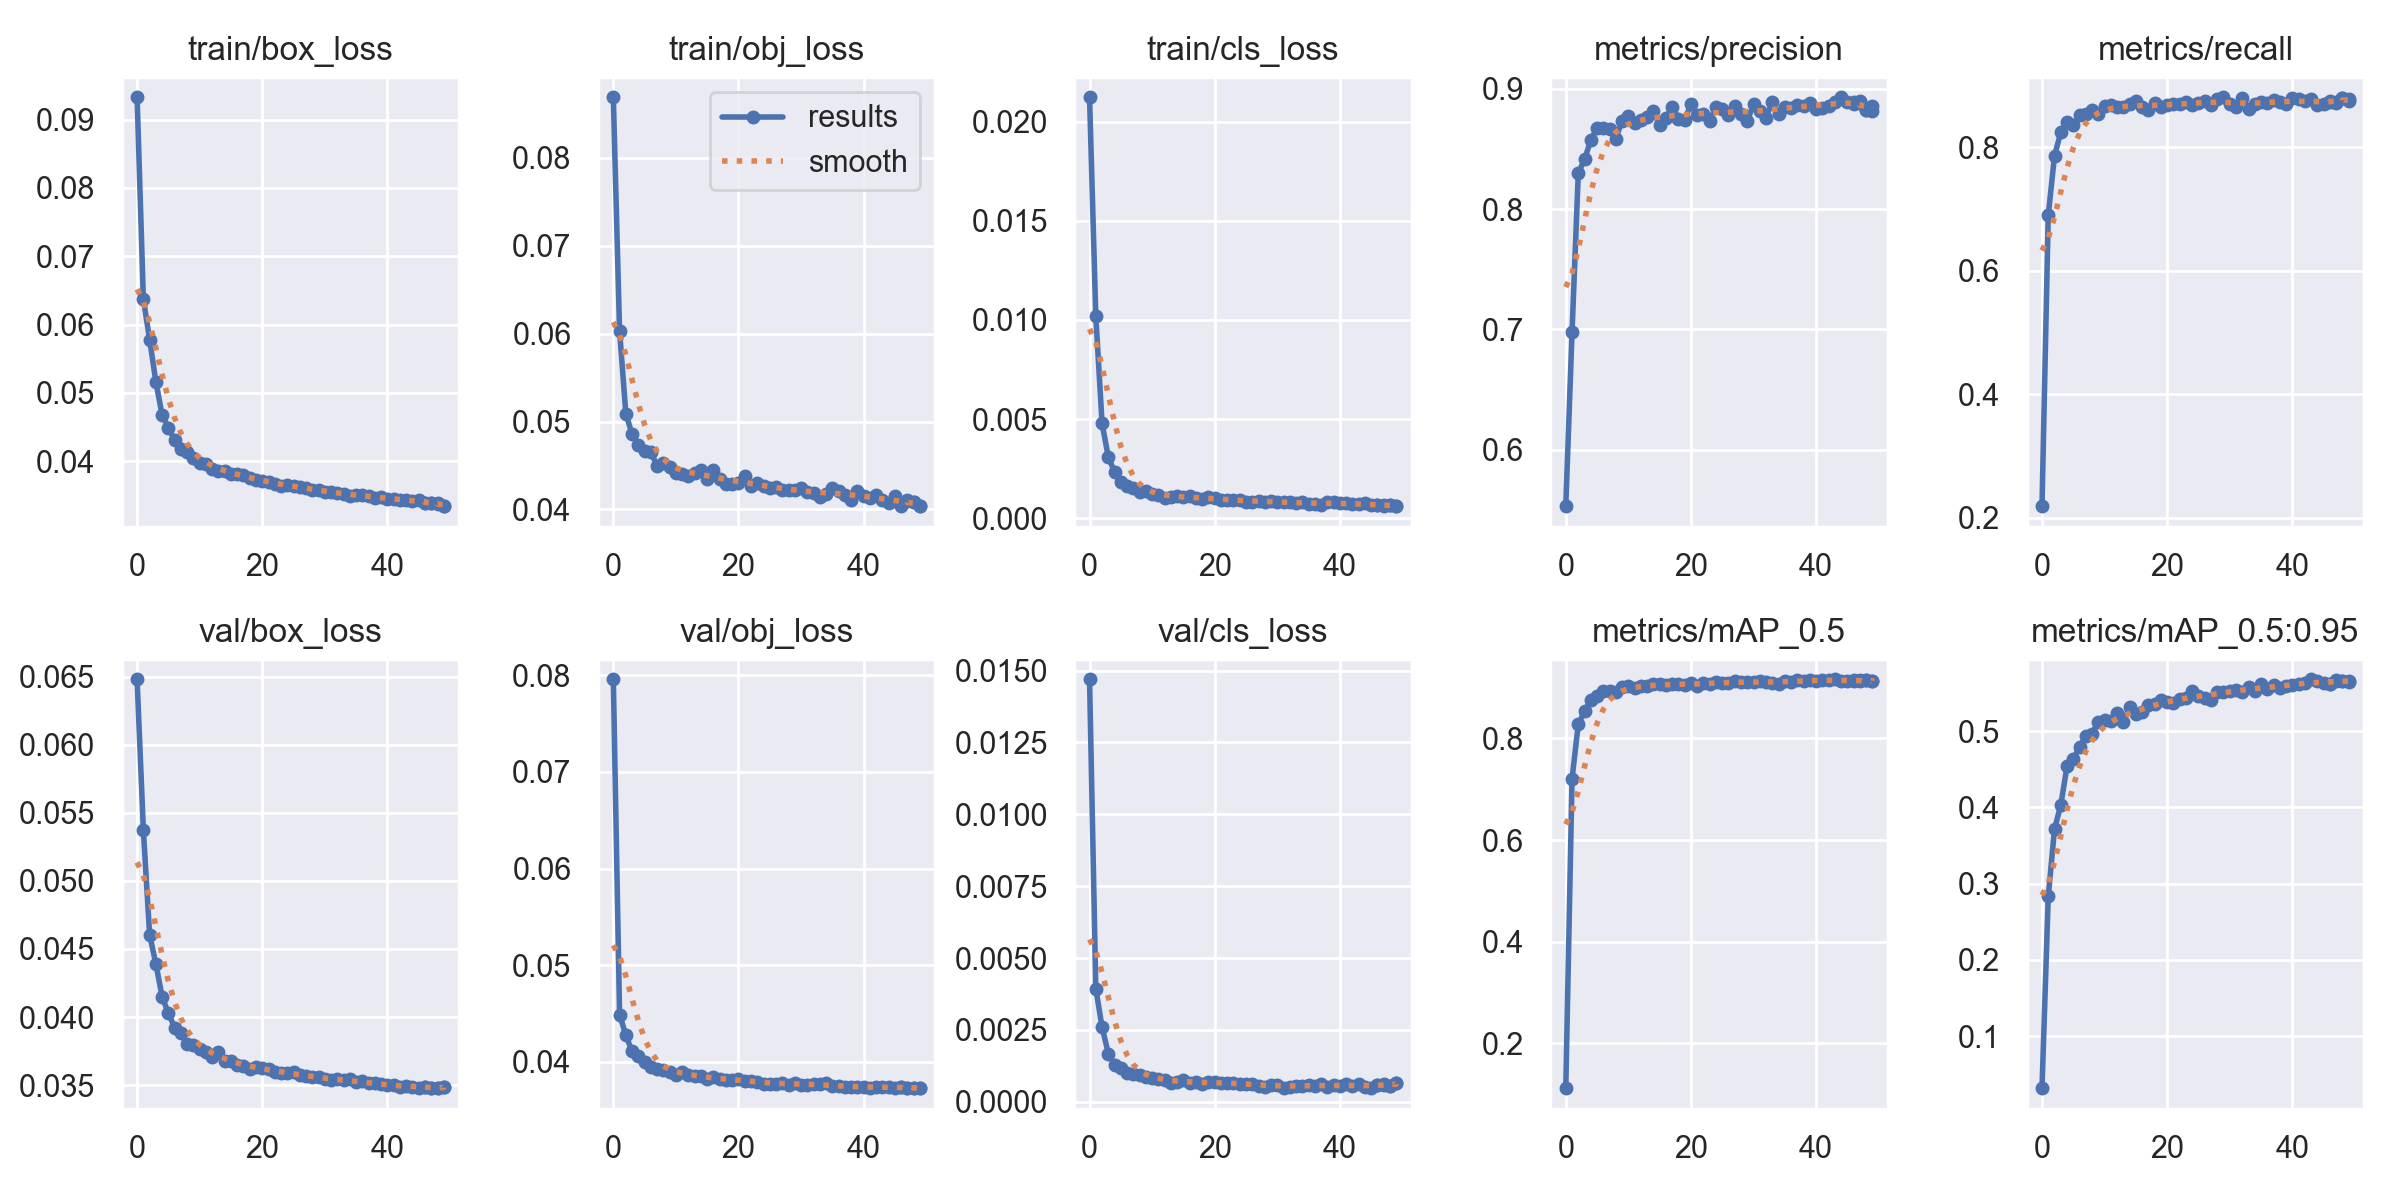

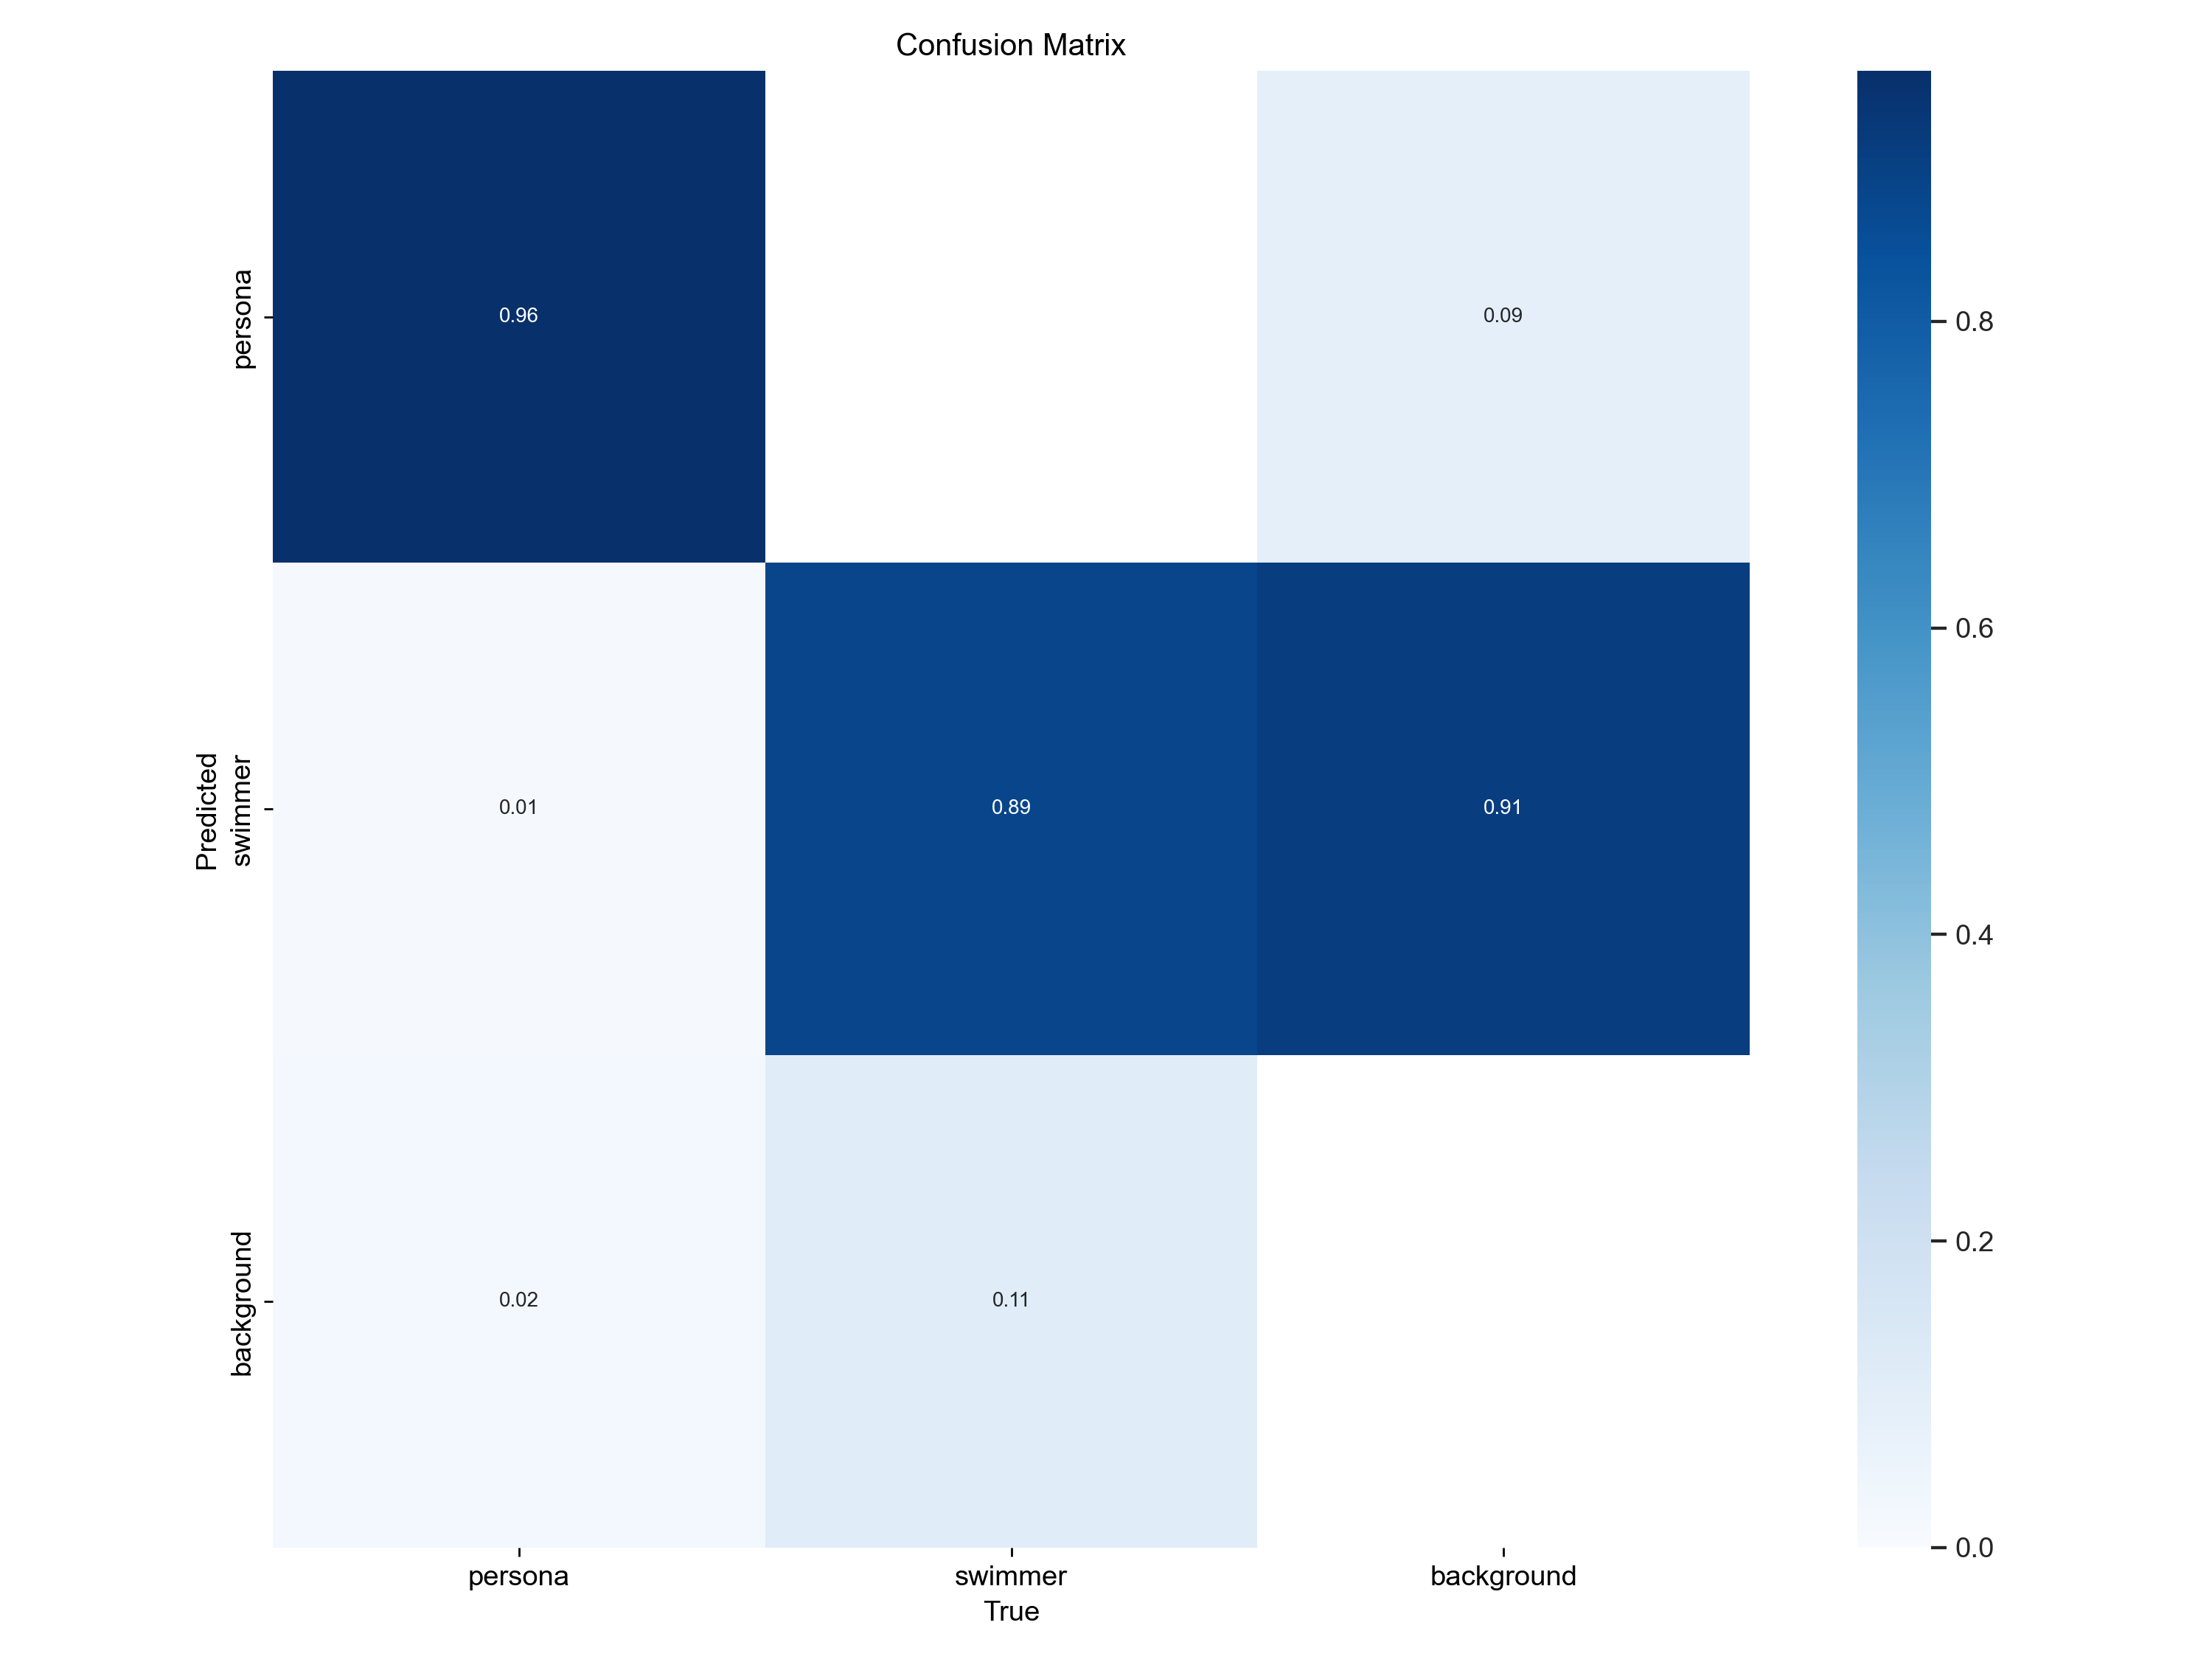

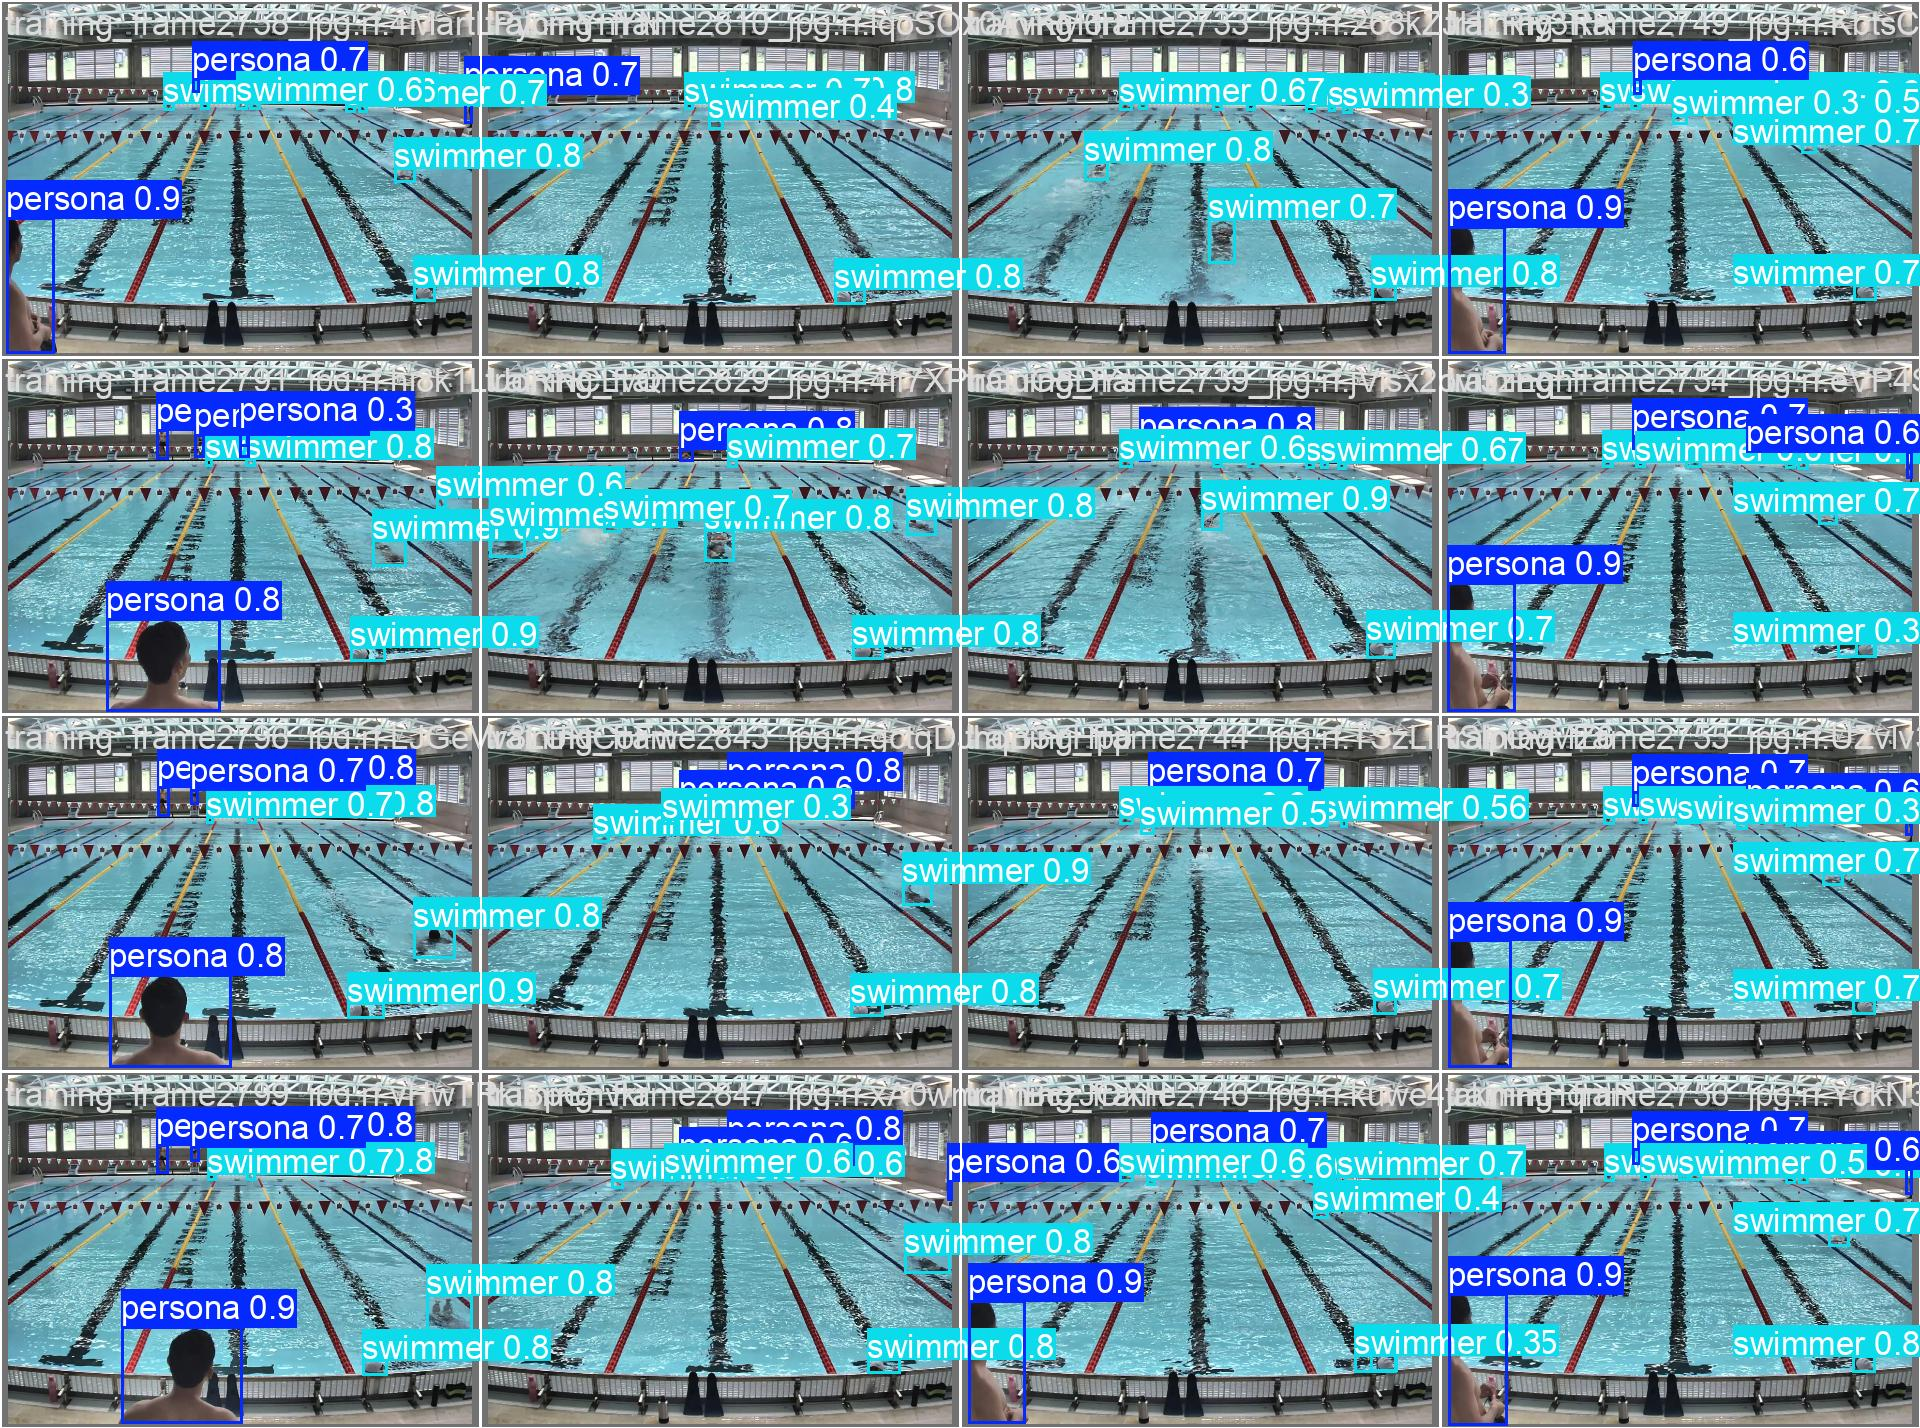

In [3]:
#@title 9. Ver resultados del entrenamiento (v3, historial completo de las 50 épocas)
from IPython.display import Image, display
run_dir = '/content/drive/MyDrive/yolo_runs/swimmer_finetune_v3'
display(Image(f'{run_dir}/results.png'))
display(Image(f'{run_dir}/confusion_matrix.png'))
display(Image(f'{run_dir}/val_batch0_pred.jpg'))


## Guardar el modelo entrenado (v3)

Copia `best.pt` a tu Google Drive con un nombre claro y lo deja listo para descargar directo al navegador.

In [4]:
#@title 10. Guardar y descargar el modelo final (v3)
import shutil
best_pt = '/content/drive/MyDrive/yolo_runs/swimmer_finetune_v3/weights/best.pt'

drive_out = '/content/drive/MyDrive/swimmer_best_finetuned_v3.pt'
shutil.copy(best_pt, drive_out)
print('Guardado en Drive:', drive_out)

from google.colab import files
files.download(best_pt)


Guardado en Drive: /content/drive/MyDrive/swimmer_best_finetuned_v3.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/yolo_runs/swimmer_finetune_v3/results.csv')
df.columns = df.columns.str.strip()
df['fitness'] = 0.1*df['metrics/mAP_0.5'] + 0.9*df['metrics/mAP_0.5:0.95']
print(df.loc[df['fitness'].idxmax(), ['epoch','metrics/mAP_0.5','metrics/mAP_0.5:0.95','fitness']])


epoch                   43.000000
metrics/mAP_0.5          0.916540
metrics/mAP_0.5:0.95     0.568180
fitness                  0.603016
Name: 43, dtype: float64
